# Experiment 2: Multiple Linear Regression

**Dataset:** California Housing dataset: 20,640 observations, 8 input features; downloaded by scikit-learn on first run.

## Aim
Implement the model, evaluate it on held-out test data, and visualize predictions and residuals.

## Note
The California Housing dataset is not a Kaggle dataset. Scikit-learn downloads and caches it when first requested; an internet connection is needed on the first run.

Dataset shape: (20640, 9)

First five rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  

Missing values: 0

Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: MedHouseVal (median house value, units of $100,000)

Training observations: 16512
Testing observations: 4128

--- Test Set Evaluation ---
MAE: 0.5332
MSE: 0.5559
RMSE: 0.7456
R2 Score: 0.5758


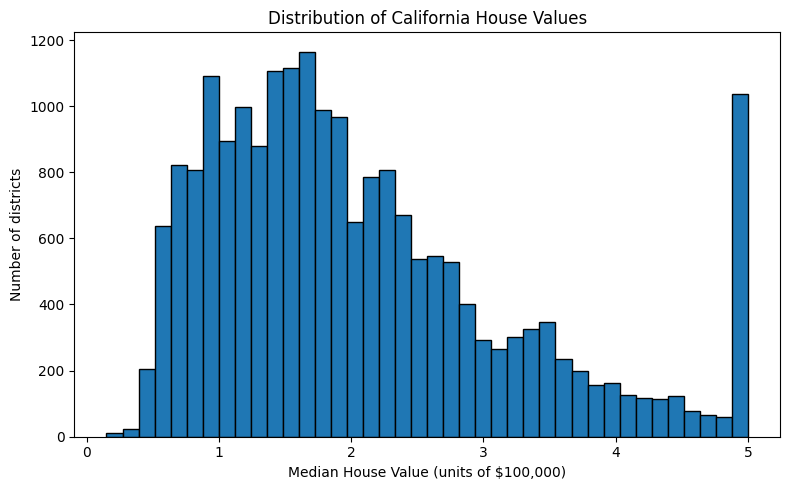

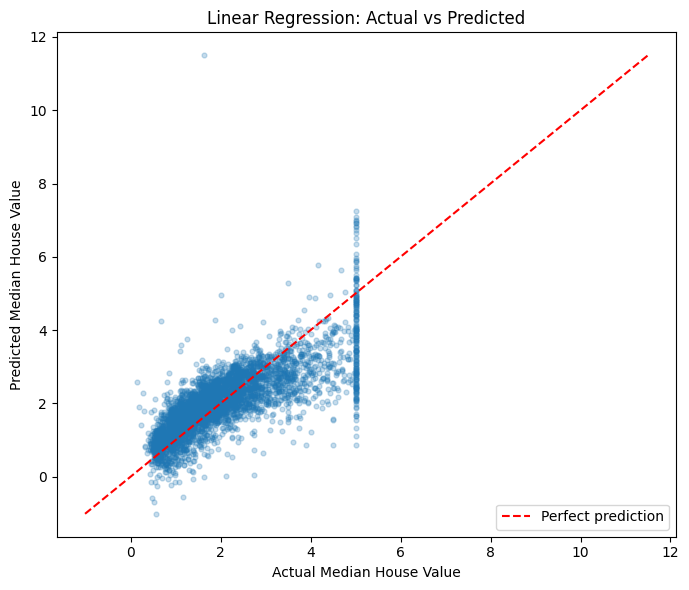

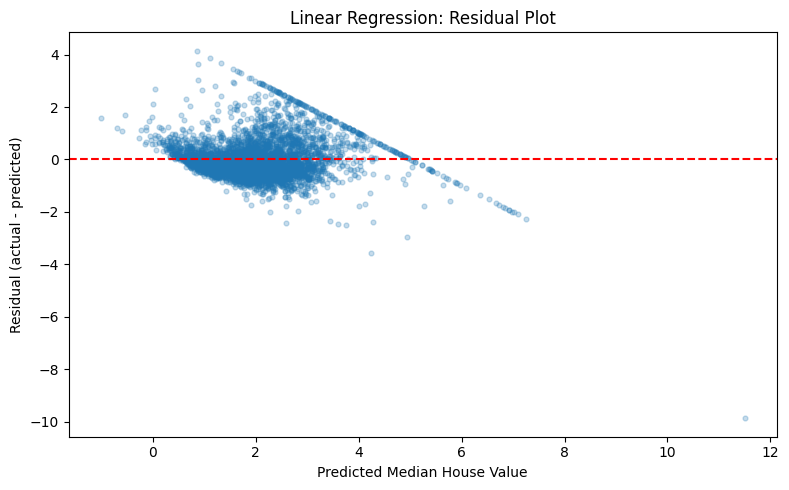


Coefficients (standardized input features; sorted by absolute value):
Latitude     -0.8969
Longitude    -0.8698
MedInc        0.8544
AveBedrms     0.3393
AveRooms     -0.2944
HouseAge      0.1225
AveOccup     -0.0408
Population   -0.0023
dtype: float64

Example input row:
 MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  Longitude
 1.6812      25.0  4.192201   1.022284      1392.0  3.877437     36.06    -119.01
Predicted median house value: 0.7191 units of $100,000
Approximate predicted value in dollars: $71,912


In [1]:
# Experiment 2: Multiple Linear Regression
# Dataset: California Housing (20,640 observations; fetched by scikit-learn)
# First run requires an internet connection to download the dataset.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Load dataset
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nMissing values:", int(df.isnull().sum().sum()))
print("\nFeatures:", list(housing.feature_names))
print("Target: MedHouseVal (median house value, units of $100,000)")

# 2. Separate input features and target
X = df[housing.feature_names]
y = df["MedHouseVal"]

# 3. Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

# 4. Build and train the model
# Scaling is included in the pipeline to keep preprocessing organized.
model = make_pipeline(StandardScaler(), LinearRegression())
model.fit(X_train, y_train)

# 5. Predict on unseen test data
y_pred = model.predict(X_test)

# 6. Evaluate model
print("\n--- Test Set Evaluation ---")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("MSE:", round(mean_squared_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

# 7. Visualization: target distribution
plt.figure(figsize=(8, 5))
plt.hist(y, bins=40, edgecolor="black")
plt.xlabel("Median House Value (units of $100,000)")
plt.ylabel("Number of districts")
plt.title("Distribution of California House Values")
plt.tight_layout()
plt.show()

# 8. Visualization: actual vs predicted values
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.25, s=12)
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.xlabel("Actual Median House Value")
plt.ylabel("Predicted Median House Value")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()
plt.show()

# 9. Visualization: residuals
residuals = y_test - y_pred
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.25, s=12)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted Median House Value")
plt.ylabel("Residual (actual - predicted)")
plt.title("Linear Regression: Residual Plot")
plt.tight_layout()
plt.show()

# 10. Display coefficients and a sample prediction
coefficients = pd.Series(
    model.named_steps["linearregression"].coef_,
    index=housing.feature_names
).sort_values(key=abs, ascending=False)
print("\nCoefficients (standardized input features; sorted by absolute value):")
print(coefficients.round(4))

sample = X_test.iloc[[0]]
sample_prediction = model.predict(sample)[0]
print("\nExample input row:")
print(sample.to_string(index=False))
print("Predicted median house value:", round(sample_prediction, 4),
      "units of $100,000")
print("Approximate predicted value in dollars:", f"${sample_prediction * 100000:,.0f}")
